# 03J 端到端 autoencoder 通信链路

本实验是对 Sionna 自带示例的课程化简化版本。请补全 TODO 并解释关键参数对结果的影响。

## 实验任务与实现思路

本实验把发射机与接收机放进同一个可微模型里联合优化（端到端自编码器）：

1. **可训练星座**：$M=4$ 个消息各对应一个二维实数星座点 $\mathbf{s}_i\in\mathbb{R}^2$，
   这是网络的参数，由梯度下降学出来；实现时先减去均值（零均值），再归一化到平均符号能量 $E_s=1$；
2. **可训练接收机**：AWGN 后得到 $\mathbf{y}=\mathbf{s}_{m}+\mathbf{w}$，把 $[\mathrm{Re}(\mathbf{y}),\mathrm{Im}(\mathbf{y}),\log_{10}N_0]$
   送入三层 MLP，输出 $M$ 类 logits，用交叉熵损失监督发送消息 $m$；
3. **训练**：模板默认在固定 $E_b/N_0=7$ dB 处训练，Adam、lr $=10^{-2}$、batch 512；
4. **补充实验**：记录训练过程中星座的演化快照、画出学习到的判决区域、比较“固定 5 dB 训练 vs 混合 0~15 dB 训练”
   学到的星座差异，并把自编码器的符号错误率与比特错误率同 QPSK 理论曲线对比。

训练数据（消息与噪声）全部由独立的 `torch.Generator` 产生，两次运行结果完全一致。

In [1]:
# 导入依赖，并准备端到端 autoencoder 通信链路。
from pathlib import Path
import sys
import time

for p in [Path.cwd(), *Path.cwd().parents]:
    if (p / "src" / "sionna").exists():
        sys.path.insert(0, str(p / "src"))
        break

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from scipy.special import erfc
from sionna.phy.channel import AWGN
from sionna.phy import config as sionna_config

DEVICE = "cpu"
PRECISION = "single"
torch.set_num_threads(8)

# 图、数据输出目录：便于把过程性与结果性材料归档到同一文件夹。
FIG_DIR = Path.cwd() / "figures"
DATA_DIR = Path.cwd() / "data"
FIG_DIR.mkdir(exist_ok=True)
DATA_DIR.mkdir(exist_ok=True)

# 设置 Matplotlib 中文字体，避免图标题和坐标轴中文显示为问号。
plt.rcParams["font.sans-serif"] = [
    "Microsoft YaHei",
    "SimHei",
    "Noto Sans CJK SC",
    "Arial Unicode MS",
    "DejaVu Sans",
]
plt.rcParams["axes.unicode_minus"] = False

# 报告插图统一字号（与 01/03A 一致）。
plt.rcParams.update(
    {
        "font.size": 13,
        "axes.labelsize": 13,
        "axes.titlesize": 13,
        "xtick.labelsize": 12,
        "ytick.labelsize": 12,
        "legend.fontsize": 11,
        "figure.dpi": 200,
        "savefig.dpi": 200,
    }
)


def set_seed(seed=42):
    """固定 Python / NumPy / PyTorch / Sionna 四个随机源，使仿真结果可复现。"""
    torch.manual_seed(seed)
    np.random.seed(seed)
    sionna_config.seed = int(seed)


set_seed(42)

import torch.nn as nn
import torch.nn.functional as F
from sionna.phy.channel import AWGN

M = 4
BITS_PER_SYMBOL = 2
TRAIN_STEPS = 3000        # 主模型训练步数（模板默认 300 步，这里加长以便星座充分收敛）
BATCH_SIZE = 512
EBNO_DB = 7.0             # 模板默认的训练信噪比
EVAL_SYMBOLS = 1_000_000  # 每个 Eb/N0 点用于统计 BER/SER 的符号数
EVAL_CHUNK = 250_000      # 分批推理，控制内存
TRAIN_GENERATOR = torch.Generator(device="cpu").manual_seed(1234)
EVAL_GENERATOR = torch.Generator(device="cpu").manual_seed(2026)
awgn = AWGN(precision=PRECISION, device=DEVICE)


def ebno_db_to_no(ebno_db, bits_per_symbol):
    ebno = 10 ** (torch.as_tensor(ebno_db, dtype=torch.float32, device=DEVICE) / 10.0)
    return 1.0 / (ebno * bits_per_symbol)


def count_bit_errors(b, b_hat):
    return int(torch.sum(b.to(torch.int32) != b_hat.to(torch.int32)).item())


def index_to_bits(idx, k=BITS_PER_SYMBOL):
    """把消息序号（0..M-1）展开成 k 个比特，高位在前，与发送端二进制标号一致。"""
    shifts = torch.arange(k - 1, -1, -1, device=idx.device)
    return ((idx.unsqueeze(-1) >> shifts) & 1).to(torch.int32)


def qfunc(z):
    return 0.5 * erfc(np.asarray(z, dtype=np.float64) / np.sqrt(2.0))


def theory_qpsk_ber(ebno_db):
    """Gray 码 QPSK 理论误比特率：Pb = 0.5*erfc(sqrt(Eb/N0))。"""
    gb = 10 ** (np.asarray(ebno_db, dtype=np.float64) / 10.0)
    return 0.5 * erfc(np.sqrt(gb))


def theory_qpsk_ser(ebno_db):
    """QPSK 理论符号错误率：Ps = 1-(1-Q(sqrt(Es/N0)))^2，其中 Es/N0 = 2*Eb/N0。"""
    gs = 2.0 * 10 ** (np.asarray(ebno_db, dtype=np.float64) / 10.0)
    q = qfunc(np.sqrt(gs))
    return 1.0 - (1.0 - q) ** 2


def estimate_rotation_deg(pts):
    """估计学习星座相对理想 QPSK（45°+90°k）的旋转角，单位度。"""
    ang = np.degrees(np.arctan2(pts[:, 1], pts[:, 0])) % 90.0
    return float(np.mean(ang - 45.0))


print(f"消息数 M = {M}，每符号 {BITS_PER_SYMBOL} bit；训练 Eb/N0 = {EBNO_DB} dB，步数 {TRAIN_STEPS}")

消息数 M = 4，每符号 2 bit；训练 Eb/N0 = 7.0 dB，步数 3000


可训练星座点形状: (4, 2)
接收机参数量: 4684


图题：端到端自编码器训练损失（固定 Eb/N0 = 7 dB）


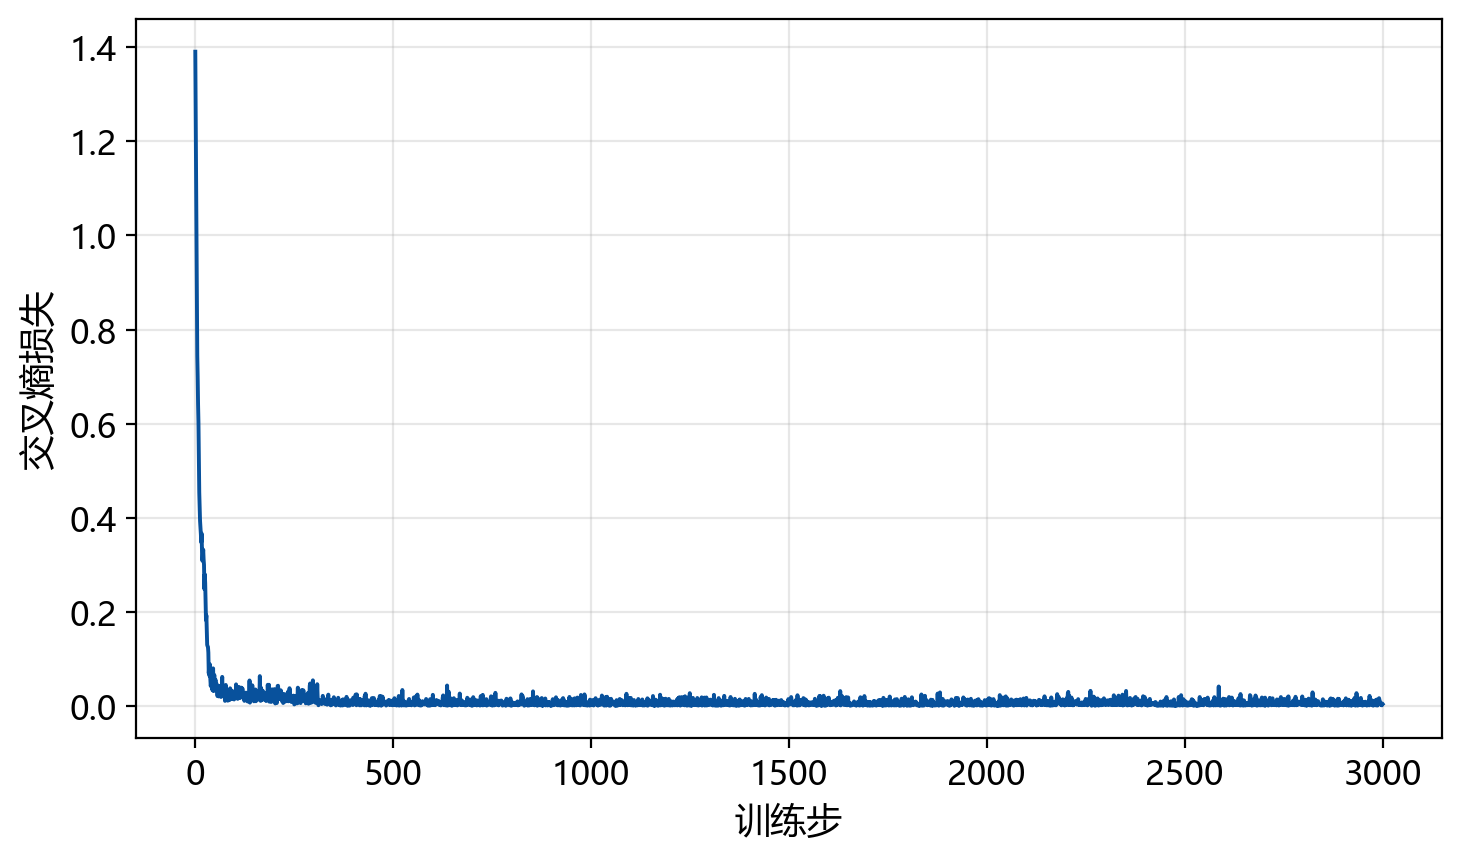

训练 3000 步耗时 4.8 s；首次损失 1.3907，最后 100 步平均损失 0.0057


In [2]:
# Autoencoder：可训练发射星座 + 神经网络接收分类器。
class CommAutoencoder(nn.Module):
    """端到端通信自编码器。

    - points: 可训练星座点，形状 (M, 2)，每行是一个消息对应的二维实数符号；
    - receiver: 接收端 MLP，输入 [Re(y), Im(y), log10(N0)]，输出 M 类 logits。

    前向过程完全是“发射 -> AWGN -> 接收”的可微仿真，因此梯度可以从
    交叉熵损失一路回传到发射星座点上，星座是“学”出来的而不是预先规定的。
    """

    def __init__(self, m=M, hidden_size=64):
        super().__init__()
        self.points = nn.Parameter(torch.randn(m, 2))
        self.receiver = nn.Sequential(
            nn.Linear(3, hidden_size),
            nn.ReLU(),
            nn.Linear(hidden_size, hidden_size),
            nn.ReLU(),
            nn.Linear(hidden_size, m),
        )

    def constellation(self):
        """对星座点做零均值与平均能量归一化，保证发送符号满足 Es = 1。"""
        p = self.points - self.points.mean(dim=0, keepdim=True)
        return p / torch.sqrt(torch.mean(torch.sum(p**2, dim=1)) + 1e-12)

    def forward(self, messages, no, generator=None):
        pts = self.constellation()
        x = pts[messages]
        no_t = torch.as_tensor(no, dtype=torch.float32, device=x.device)
        if generator is None:
            noise = torch.randn_like(x)
        else:
            noise = torch.randn(x.shape, dtype=torch.float32, generator=generator)
        # 每个实数维度方差 no/2，两维合成复方差 no
        y = x + noise * torch.sqrt(no_t / 2.0)
        feat = torch.cat([y, torch.log10(no_t).expand(x.shape[0], 1)], dim=1)
        return self.receiver(feat), y


model = CommAutoencoder().to(DEVICE)
print("可训练星座点形状:", tuple(model.points.shape))
print("接收机参数量:", sum(p.numel() for p in model.receiver.parameters()) + model.points.numel())

opt = torch.optim.Adam(model.parameters(), lr=1e-2)
losses = []
no = ebno_db_to_no(EBNO_DB, bits_per_symbol=2)

# 训练过程中记录星座快照，用于展示“星座是从数据里学出来的”。
SNAPSHOT_STEPS = (50, 200)
constellation_snapshots = {0: model.constellation().detach().cpu().numpy().copy()}

t0 = time.perf_counter()
for step in range(TRAIN_STEPS):
    msg = torch.randint(0, M, (BATCH_SIZE,), dtype=torch.long, device=DEVICE, generator=TRAIN_GENERATOR)
    logits, _ = model(msg, no, generator=TRAIN_GENERATOR)
    loss = F.cross_entropy(logits, msg)
    opt.zero_grad()
    loss.backward()
    opt.step()
    losses.append(float(loss.item()))
    if step + 1 in SNAPSHOT_STEPS:
        constellation_snapshots[step + 1] = model.constellation().detach().cpu().numpy().copy()
train_time = time.perf_counter() - t0
constellation_snapshots[TRAIN_STEPS] = model.constellation().detach().cpu().numpy().copy()

plt.figure(figsize=(7.5, 4.5))
plt.plot(np.arange(1, len(losses) + 1), losses, lw=1.4, color="#08519c")
plt.xlabel("训练步")
plt.ylabel("交叉熵损失")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIG_DIR / "03J_train_loss.png", dpi=200, bbox_inches="tight")
print("图题：端到端自编码器训练损失（固定 Eb/N0 = 7 dB）")
plt.show()

print(
    f"训练 {TRAIN_STEPS} 步耗时 {train_time:.1f} s；首次损失 {losses[0]:.4f}，"
    f"最后 100 步平均损失 {np.mean(losses[-100:]):.4f}"
)
pd.DataFrame({"step": np.arange(1, len(losses) + 1), "loss": losses}).to_csv(
    DATA_DIR / "03J_train_loss.csv", index=False, encoding="utf-8-sig"
)

assert losses[-1] < losses[0]

图题：端到端学习得到的 4 点星座与理想 QPSK 星座对比


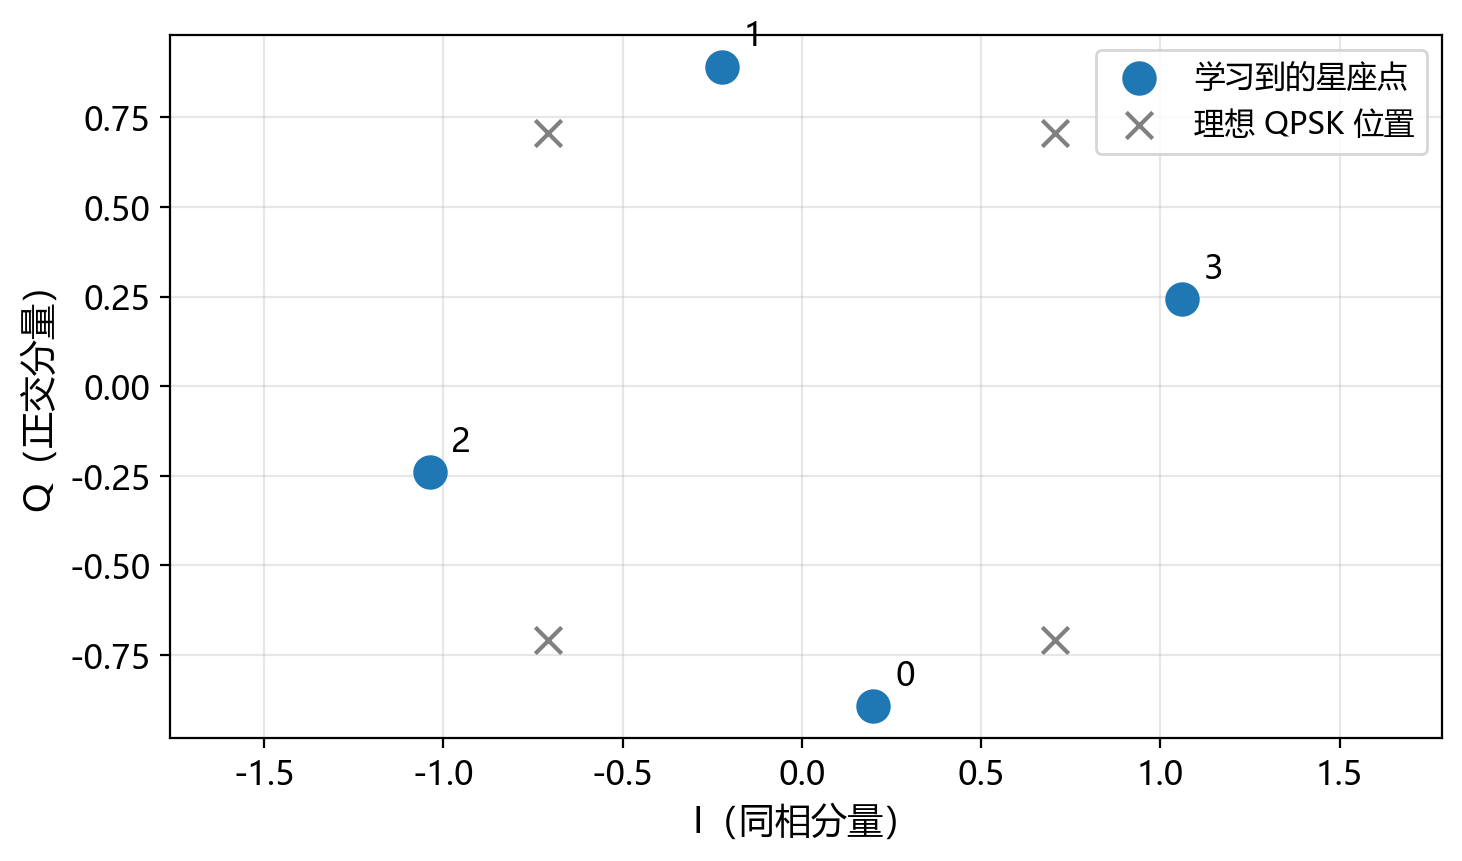

学习到的星座点坐标（Es 归一化后）：
  消息 0（00）: (+0.200, -0.893)
  消息 1（01）: (-0.223, +0.891)
  消息 2（10）: (-1.037, -0.240)
  消息 3（11）: (+1.061, +0.242)
平均符号能量 = 1.0000，相对理想 QPSK 的旋转角 ≈ -31.8°


In [3]:
# 可视化学习到的星座点。
with torch.no_grad():
    pts = model.constellation().cpu().numpy()

plt.figure(figsize=(7.5, 4.5))
plt.scatter(pts[:, 0], pts[:, 1], s=130, zorder=3, label="学习到的星座点")
for i, (x, y) in enumerate(pts):
    plt.text(x + 0.06, y + 0.06, str(i), fontsize=12)
ref = np.array([[1, 1], [-1, 1], [1, -1], [-1, -1]], dtype=float) / np.sqrt(2.0)
plt.scatter(ref[:, 0], ref[:, 1], marker="x", s=90, c="gray", label="理想 QPSK 位置")
plt.xlabel("I（同相分量）")
plt.ylabel("Q（正交分量）")
plt.xlim(-1.6, 1.6)
plt.ylim(-1.6, 1.6)
plt.axis("equal")
plt.grid(alpha=0.3)
plt.legend(loc="upper right")
plt.tight_layout()
plt.savefig(FIG_DIR / "03J_learned_constellation.png", dpi=200, bbox_inches="tight")
print("图题：端到端学习得到的 4 点星座与理想 QPSK 星座对比")
plt.show()

print("学习到的星座点坐标（Es 归一化后）：")
for i, (x, y) in enumerate(pts):
    print(f"  消息 {i}（{format(i, '02b')}）: ({x:+.3f}, {y:+.3f})")
print(
    f"平均符号能量 = {float(np.mean(np.sum(pts**2, axis=1))):.4f}，"
    f"相对理想 QPSK 的旋转角 ≈ {estimate_rotation_deg(pts):+.1f}°"
)

assert pts.shape == (M, 2)

## 补充实验一：星座的演化过程与学到的判决区域

自编码器与“人工设计 QPSK”最大的区别是：星座点、以及接收端的判决边界，都是优化器从随机初值开始自己找出来的。
先看训练第 0、50、200、3000 步的星座快照，再把接收机在整个 $I$-$Q$ 平面上的判决类别画出来，
检查它是否收敛到了与 QPSK 等价的方形星座和 Voronoi 判决分区。

图题：自编码器星座在训练过程中的演化（随机初值 -> 旋转 QPSK）


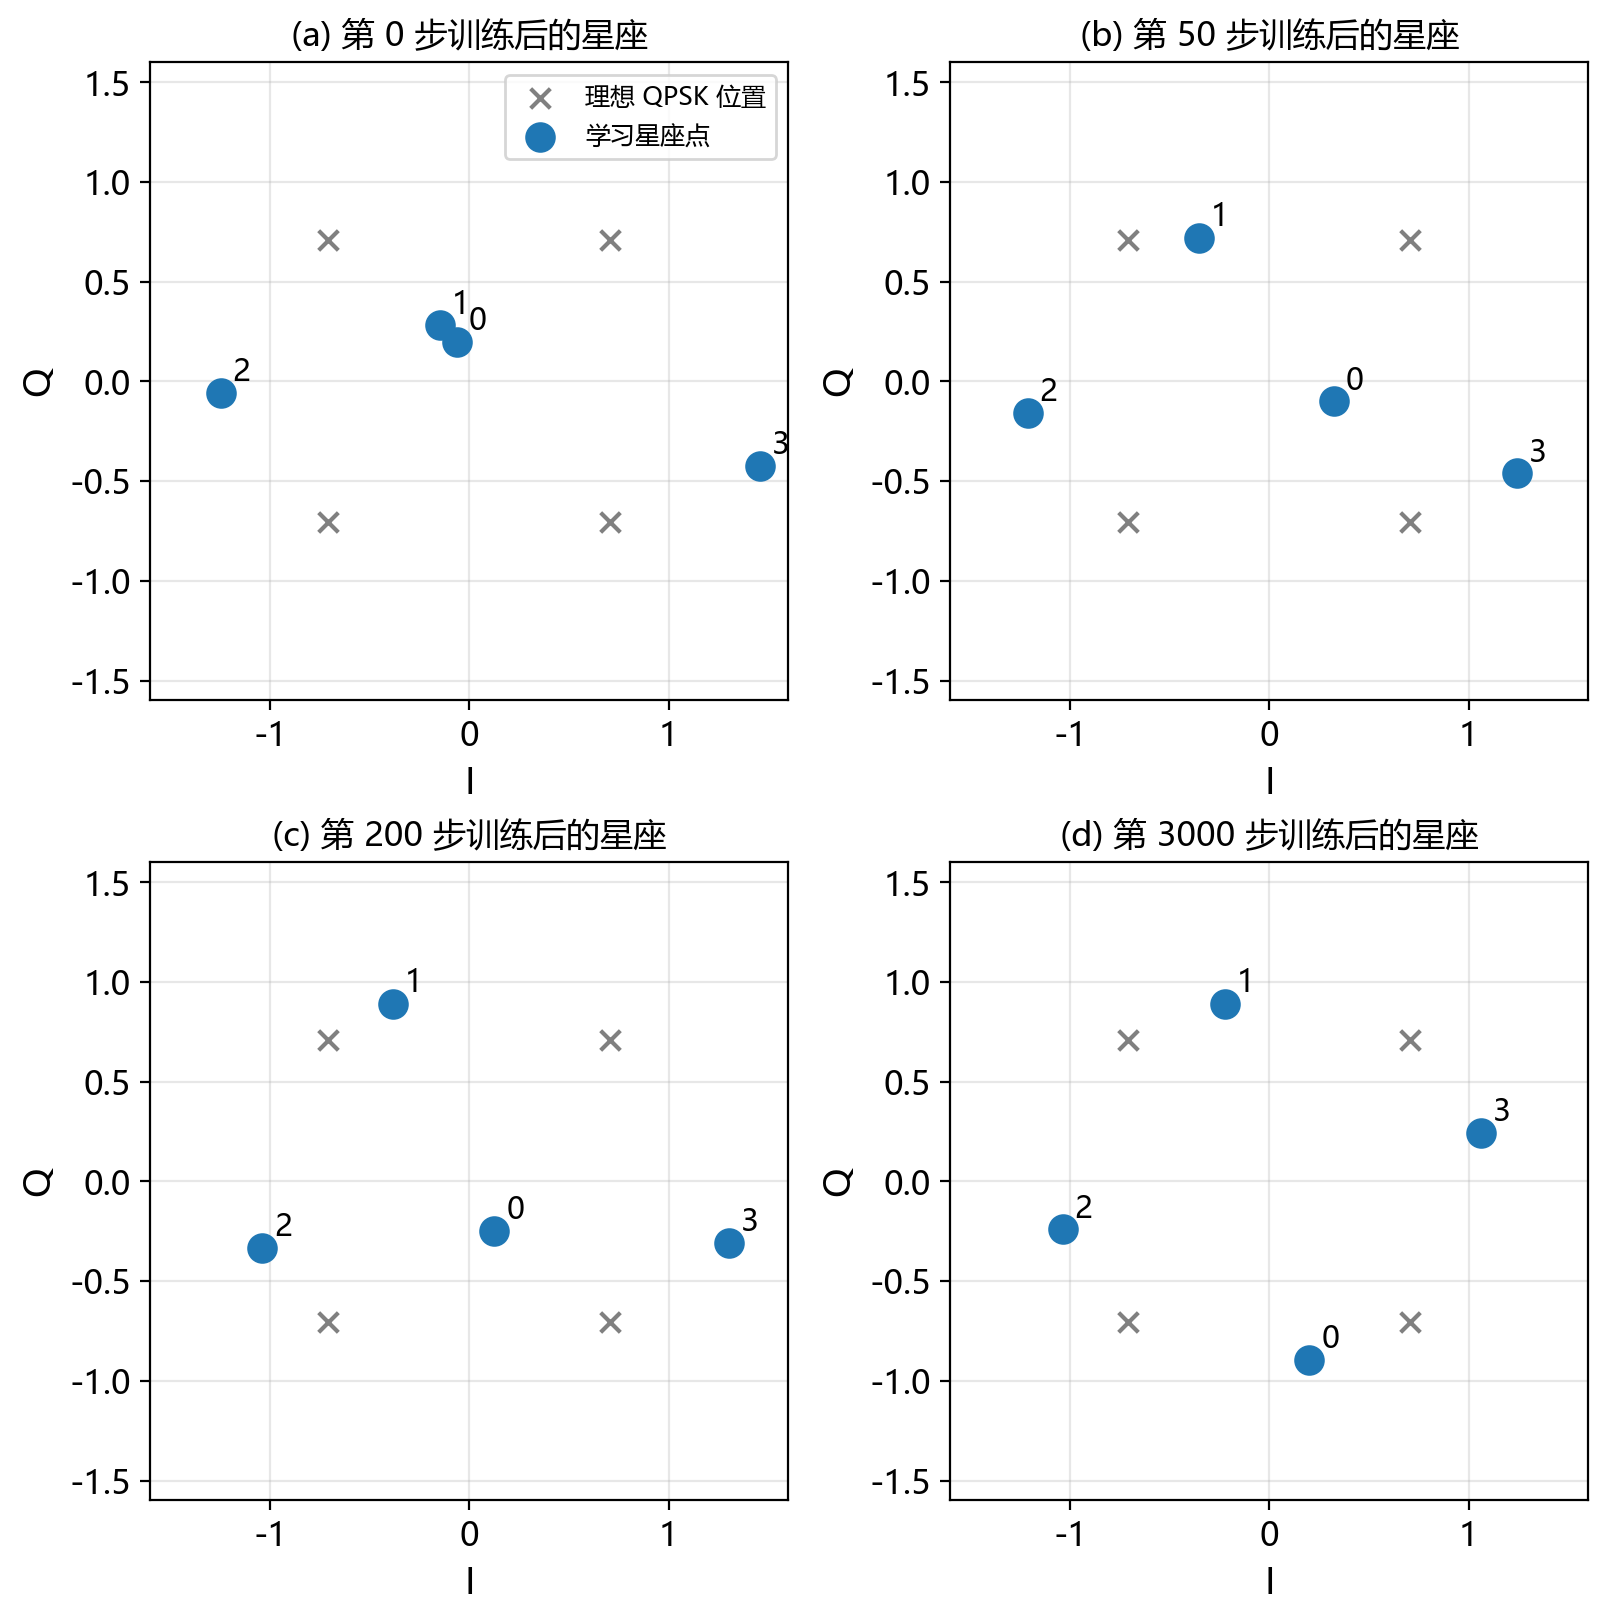

In [4]:
# 补充实验一（a）：训练过程中的星座快照。
steps = sorted(constellation_snapshots)
fig, axes = plt.subplots(2, 2, figsize=(8, 8), layout="constrained")
for ax, s, tag in zip(axes.ravel(), steps, "abcd"):
    pts_s = constellation_snapshots[s]
    ref = np.array([[1, 1], [-1, 1], [1, -1], [-1, -1]], dtype=float) / np.sqrt(2.0)
    ax.scatter(ref[:, 0], ref[:, 1], marker="x", s=50, c="gray", label="理想 QPSK 位置")
    ax.scatter(pts_s[:, 0], pts_s[:, 1], s=100, zorder=3, label="学习星座点")
    for i, (x, y) in enumerate(pts_s):
        ax.text(x + 0.06, y + 0.06, str(i), fontsize=11)
    ax.set_xlim(-1.6, 1.6)
    ax.set_ylim(-1.6, 1.6)
    ax.set_aspect("equal")
    ax.grid(alpha=0.3)
    ax.set_xlabel("I")
    ax.set_ylabel("Q")
    ax.set_title(f"({tag}) 第 {s} 步训练后的星座", fontsize=12)
axes[0, 0].legend(loc="upper right", fontsize=9)
plt.savefig(FIG_DIR / "03J_constellation_evolution.png", dpi=200, bbox_inches="tight")
print("图题：自编码器星座在训练过程中的演化（随机初值 -> 旋转 QPSK）")
plt.show()

图题：自编码器接收机在 Eb/N0 = 7 dB 时的判决区域


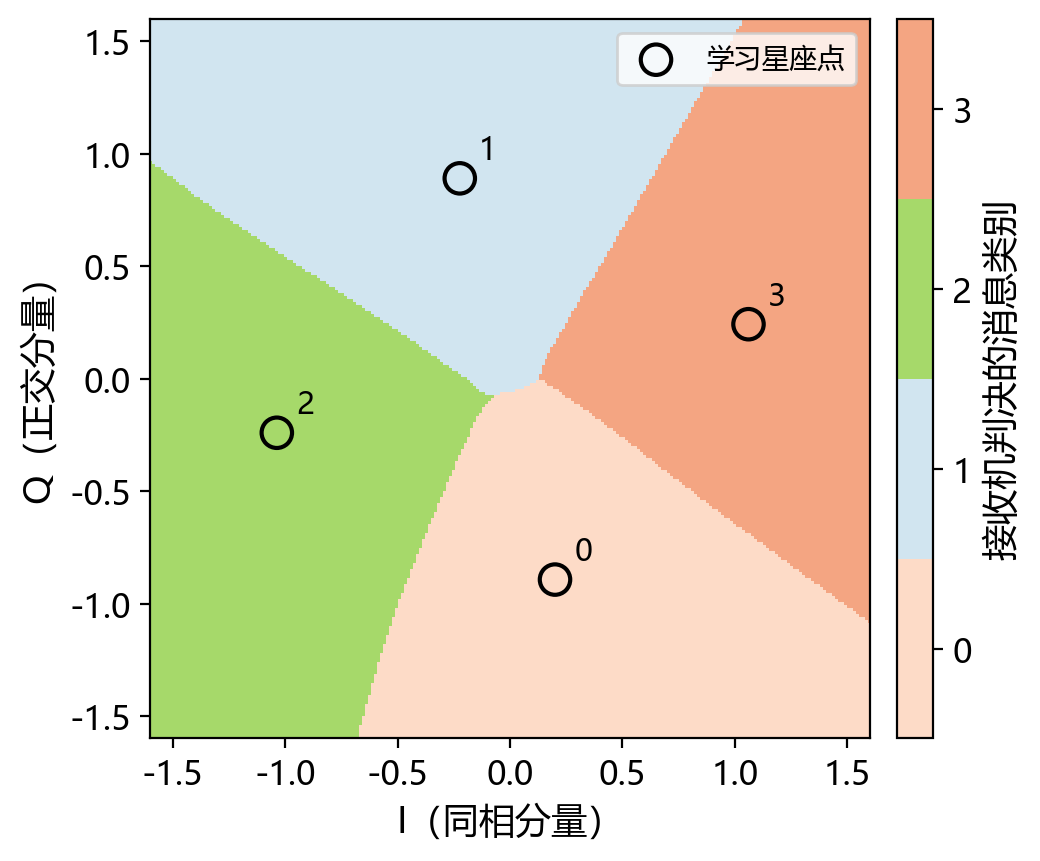

网络判决与最近邻（Voronoi）判决在 241x241 网格上的重合率：95.96%


In [5]:
# 补充实验一（b）：学习到的判决区域（无噪声判决，仅由接收机网络决定）。
from matplotlib.colors import ListedColormap


def decision_map(model, ebno_db, n=241, span=1.6):
    """在 I-Q 平面上得到接收机判为哪一类消息。"""
    grid = torch.linspace(-span, span, n)
    gi, gq = torch.meshgrid(grid, grid, indexing="ij")
    y_grid = torch.complex(gi, gq)
    no = ebno_db_to_no(ebno_db, BITS_PER_SYMBOL)
    with torch.no_grad():
        log_no = float(torch.log10(torch.as_tensor(no, dtype=torch.float32)))
        feat = torch.stack(
            [y_grid.real, y_grid.imag, torch.full_like(y_grid.real, log_no)],
            dim=-1,
        )
        logits = model.receiver(feat)
    return gi.numpy(), gq.numpy(), logits.argmax(dim=-1).numpy()


gi, gq, cls = decision_map(model, EBNO_DB)
fig, ax = plt.subplots(figsize=(7.5, 4.5))
cmap = ListedColormap(["#fddbc7", "#d1e5f0", "#a6d96a", "#f4a582"])
mesh = ax.pcolormesh(gi, gq, cls, cmap=cmap, vmin=-0.5, vmax=M - 0.5, shading="auto")
pts = model.constellation().detach().cpu().numpy()
ax.scatter(pts[:, 0], pts[:, 1], s=120, marker="o", facecolors="none", edgecolors="k", linewidths=1.5, zorder=3, label="学习星座点")
for i, (x, y) in enumerate(pts):
    ax.annotate(str(i), (x, y), xytext=(7, 7), textcoords="offset points", fontsize=11)
ax.set_xlabel("I（同相分量）")
ax.set_ylabel("Q（正交分量）")
ax.set_xlim(-1.6, 1.6)
ax.set_ylim(-1.6, 1.6)
ax.set_aspect("equal")
fig.colorbar(mesh, ax=ax, fraction=0.046, pad=0.02, ticks=range(M), label="接收机判决的消息类别")
ax.legend(loc="upper right", fontsize=10)
plt.tight_layout()
plt.savefig(FIG_DIR / "03J_decision_regions.png", dpi=200, bbox_inches="tight")
print("图题：自编码器接收机在 Eb/N0 = 7 dB 时的判决区域")
plt.show()

# 判决区域与“最近星座点”判决的一致率：若接近 100%，说明网络学到了等价的最近邻规则。
nn_label = np.argmin(
    np.abs(gi[..., None] + 1j * gq[..., None] - (pts[:, 0] + 1j * pts[:, 1])[None, None, :]),
    axis=-1,
)
agree = float((nn_label == cls).mean())
print(f"网络判决与最近邻（Voronoi）判决在 241x241 网格上的重合率：{agree:.2%}")
pd.DataFrame({"grid_size": [241], "agreement_with_voronoi": [agree]}).to_csv(
    DATA_DIR / "03J_decision_agreement.csv", index=False, encoding="utf-8-sig"
)

## 补充实验二：训练信噪比不同时学到的星座（消融实验）

星座形状本身是由**信道统计**决定的：若信道是纯 AWGN，任何旋转/镜像的方形星座都同样最优，
所以“学出来的星座”在很大程度上反映的是初始化与训练噪声水平。下面用相同的网络、
相同的训练步数，只改变训练时的 $E_b/N_0$：
(a) 固定在 5 dB；(b) 在 0~15 dB 均匀混合。比较两者收敛到的星座位置与形状。

固定 5 dB: 3000 步耗时 4.9 s，最后 100 步平均损失 0.0361


混合 0~15 dB: 3000 步耗时 5.3 s，最后 100 步平均损失 0.0597


图题：训练信噪比不同时端到端学到的星座与损失曲线对比


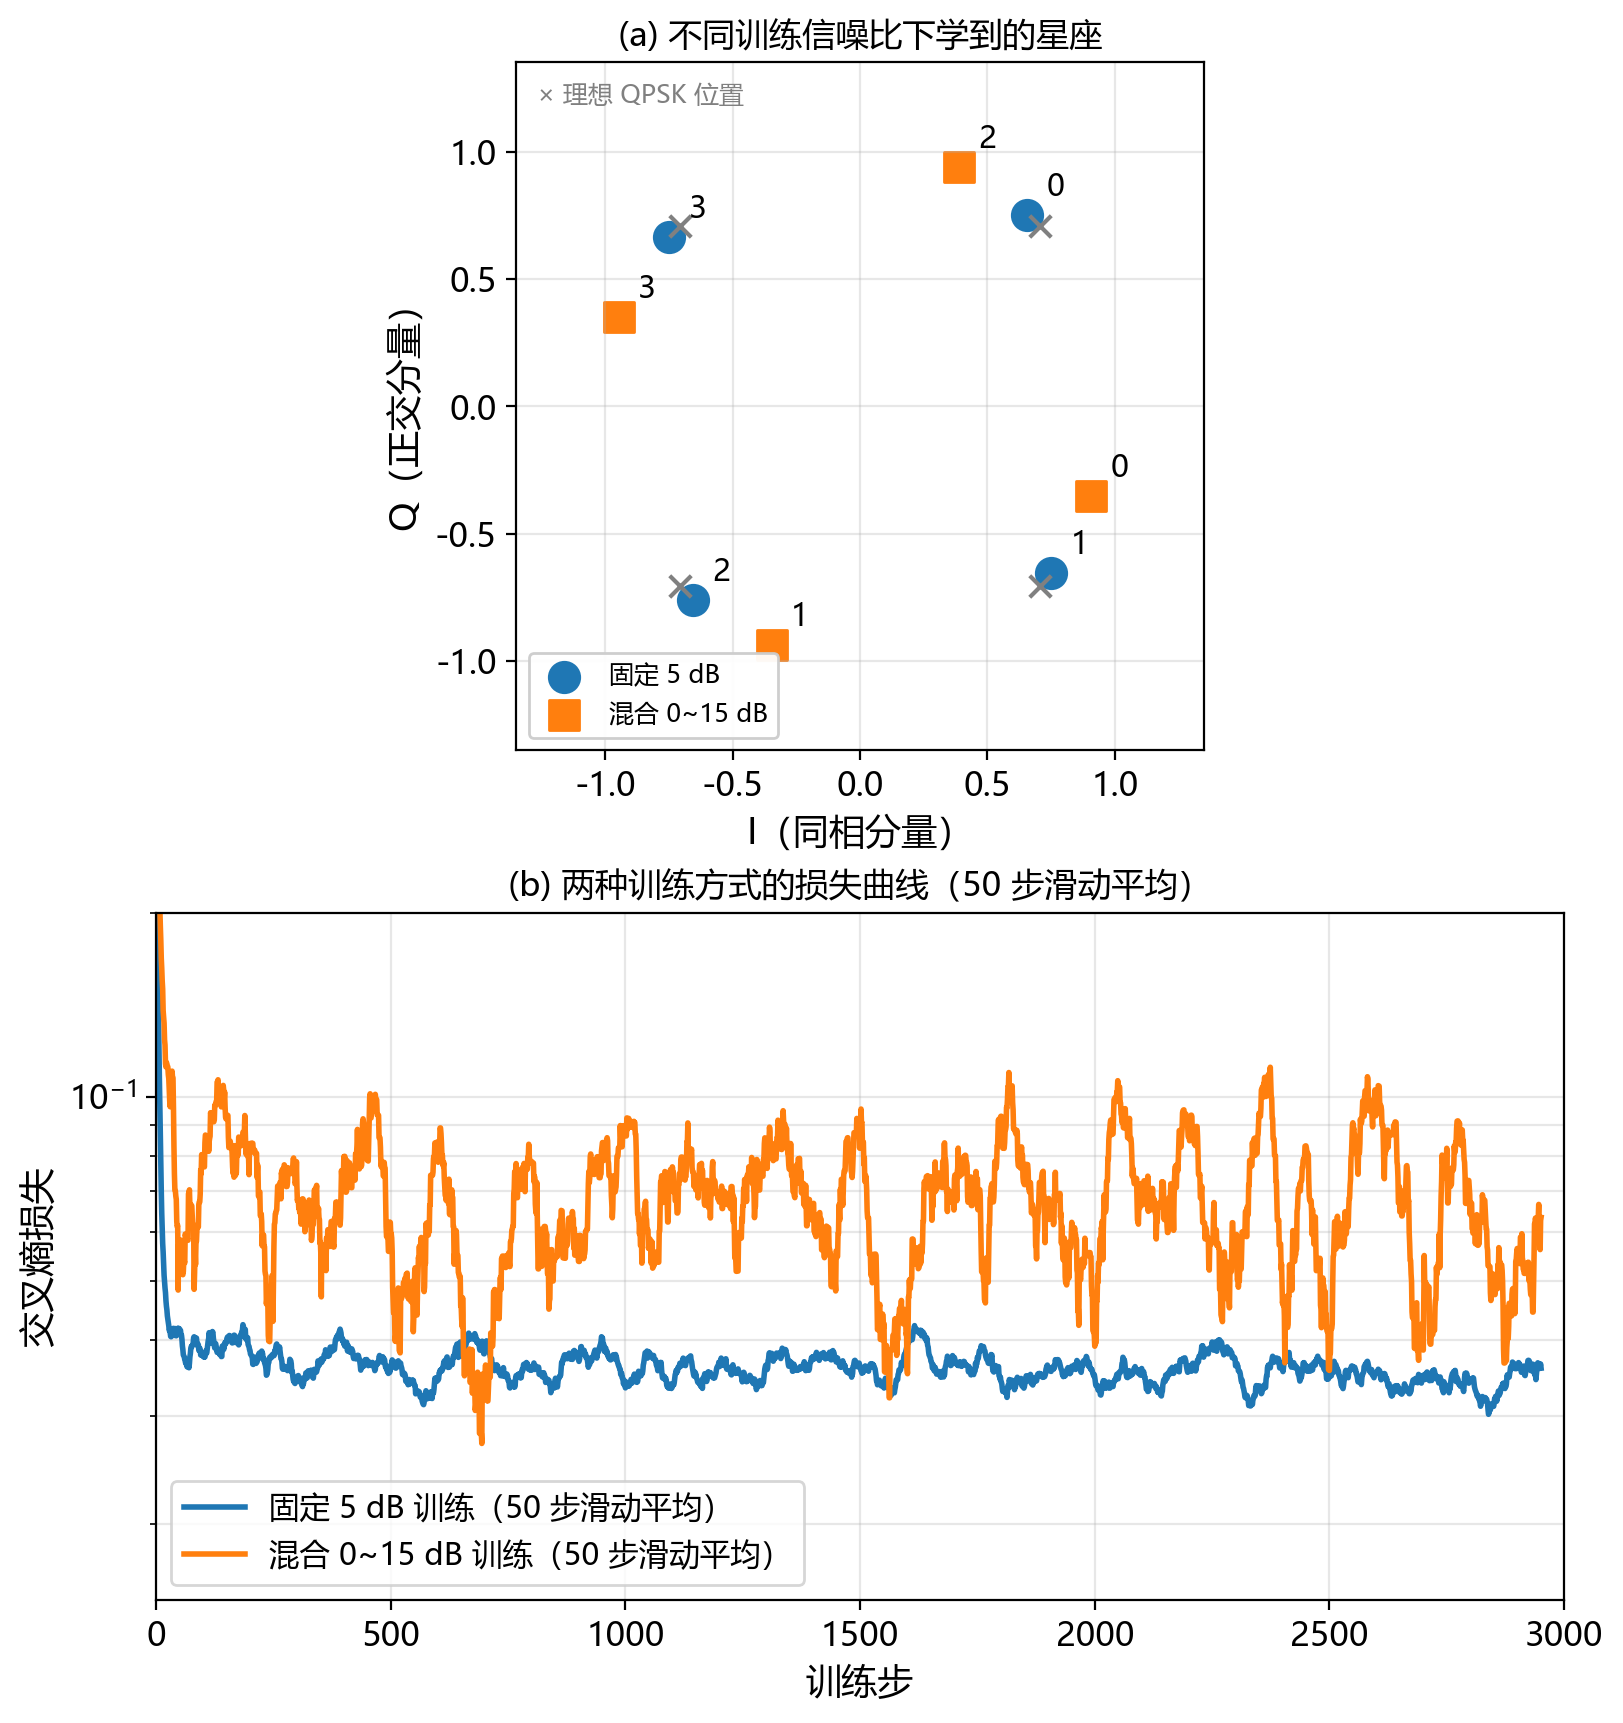

固定 5 dB：平均能量 1.0000，旋转角 ≈ +3.9°，最小点距 1.407
混合 0~15 dB：平均能量 1.0000，旋转角 ≈ +23.9°，最小点距 1.383


In [6]:
# 补充实验二：训练 SNR 消融（固定 5 dB vs 混合 0~15 dB）。
def train_autoencoder(model, num_steps, ebno_db_range, generator, label=""):
    """在给定训练信噪比范围（上下界相等即为固定 SNR）内训练自编码器。"""
    opt = torch.optim.Adam(model.parameters(), lr=1e-2)
    losses = []
    lo_db, hi_db = ebno_db_range
    t_start = time.perf_counter()
    for step in range(num_steps):
        if hi_db > lo_db:
            ebno_db = lo_db + torch.rand(1, generator=generator).item() * (hi_db - lo_db)
        else:
            ebno_db = lo_db
        no = ebno_db_to_no(ebno_db, BITS_PER_SYMBOL)
        msg = torch.randint(0, M, (BATCH_SIZE,), dtype=torch.long, device=DEVICE, generator=generator)
        logits, _ = model(msg, no, generator=generator)
        loss = F.cross_entropy(logits, msg)
        opt.zero_grad()
        loss.backward()
        opt.step()
        losses.append(float(loss.item()))
    print(
        f"{label}: {num_steps} 步耗时 {time.perf_counter() - t_start:.1f} s，"
        f"最后 100 步平均损失 {np.mean(losses[-100:]):.4f}"
    )
    return losses


ae_fixed5 = CommAutoencoder().to(DEVICE)
losses_fixed5 = train_autoencoder(
    ae_fixed5, 3000, (5.0, 5.0), torch.Generator(device="cpu").manual_seed(2026), "固定 5 dB"
)
ae_mixed = CommAutoencoder().to(DEVICE)
losses_mixed = train_autoencoder(
    ae_mixed, 3000, (0.0, 15.0), torch.Generator(device="cpu").manual_seed(2027), "混合 0~15 dB"
)

pd.DataFrame(
    {
        "step": np.arange(1, 3001),
        "loss_fixed5": losses_fixed5,
        "loss_mixed": losses_mixed,
    }
).to_csv(DATA_DIR / "03J_ablation_train_loss.csv", index=False, encoding="utf-8-sig")

# 三种训练信噪比下的星座 + 训练损失曲线
fig, axes = plt.subplots(2, 1, figsize=(8, 8.5), layout="constrained")
ax = axes[0]
setups = [
    ("固定 5 dB", ae_fixed5, "o"),
    ("混合 0~15 dB", ae_mixed, "s"),
]
for label, mdl, marker in setups:
    p = mdl.constellation().detach().cpu().numpy()
    ax.scatter(p[:, 0], p[:, 1], marker=marker, s=120, label=label)
    for i, (x, y) in enumerate(p):
        ax.annotate(str(i), (x, y), xytext=(7, 7), textcoords="offset points", fontsize=11)
ref = np.array([[1, 1], [-1, 1], [1, -1], [-1, -1]], dtype=float) / np.sqrt(2.0)
ax.scatter(ref[:, 0], ref[:, 1], marker="x", s=60, c="gray")
ax.text(
    0.03,
    0.97,
    "× 理想 QPSK 位置",
    transform=ax.transAxes,
    va="top",
    fontsize=9,
    color="gray",
)
ax.set_xlim(-1.35, 1.35)
ax.set_ylim(-1.35, 1.35)
ax.set_aspect("equal", adjustable="box")
ax.grid(alpha=0.3)
ax.set_xlabel("I（同相分量）")
ax.set_ylabel("Q（正交分量）")
ax.legend(loc="lower left", fontsize=9, framealpha=0.95)
ax.set_title("(a) 不同训练信噪比下学到的星座", fontsize=12)

ax = axes[1]


def moving_average(x, w=50):
    """长度为 w 的滑动平均，用于看清损失曲线的下降趋势。"""
    x = np.asarray(x, dtype=float)
    return np.convolve(x, np.ones(w) / w, mode="valid")


steps_axis = np.arange(1, len(losses_fixed5) + 1)
for losses, color, label in [
    (losses_fixed5, "tab:blue", "固定 5 dB 训练"),
    (losses_mixed, "tab:orange", "混合 0~15 dB 训练"),
]:
    smooth = moving_average(losses)
    ax.plot(steps_axis[: len(smooth)], smooth, lw=2.0, color=color, label=f"{label}（50 步滑动平均）")
ax.set_yscale("log")
ax.set_ylim(1.5e-2, 2e-1)
ax.set_xlim(0, 3000)
ax.set_xlabel("训练步")
ax.set_ylabel("交叉熵损失")
ax.grid(True, which="both", alpha=0.3)
ax.legend(loc="lower left")
ax.set_title("(b) 两种训练方式的损失曲线（50 步滑动平均）", fontsize=12)

plt.savefig(FIG_DIR / "03J_ablation_constellation.png", dpi=200, bbox_inches="tight")
print("图题：训练信噪比不同时端到端学到的星座与损失曲线对比")
plt.show()

for label, mdl, _marker in setups:
    p = mdl.constellation().detach().cpu().numpy()
    print(
        f"{label}：平均能量 {float(np.mean(np.sum(p**2, axis=1))):.4f}，"
        f"旋转角 ≈ {estimate_rotation_deg(p):+.1f}°，"
        f"最小点距 {float(np.min(np.linalg.norm(p[:, None, :] - p[None, :, :], axis=-1) + np.eye(M) * 9)):.3f}"
    )

pd.DataFrame(
    [
        ("fixed5", i, p[0], p[1], format(i, "02b"))
        for i, p in enumerate(ae_fixed5.constellation().detach().cpu().numpy())
    ]
    + [
        ("mixed0_15", i, p[0], p[1], format(i, "02b"))
        for i, p in enumerate(ae_mixed.constellation().detach().cpu().numpy())
    ]
    + [
        ("main7", i, p[0], p[1], format(i, "02b"))
        for i, p in enumerate(model.constellation().detach().cpu().numpy())
    ],
    columns=["model", "message", "I", "Q", "bits"],
).to_csv(DATA_DIR / "03J_constellation.csv", index=False, encoding="utf-8-sig")

## 补充实验三：BER / SER 与 QPSK 理论对比

自编码器输出的是 $M$ 类后验，天然给出**符号**判决；比特错误率要按“消息序号 -> 比特”的标号换算。
由于交叉熵只在消息层面监督、并不约束标号顺序，训练后消息标签在星座上的排布可能不是 Gray 码，
因此这里同时给出符号错误率 SER（只取决于星座几何与判决区域）与比特错误率 BER（还与标号有关），
并和 QPSK 的解析理论曲线对比，用来区分“几何是否学到”和“标号是否学到”。

Eb/N0(dB)  理论BER    7dB训练BER   混合训练BER   理论SER    7dB训练SER   混合训练SER
     0.0  7.865e-02    1.187e-01     7.946e-02  1.511e-01   1.597e-01     1.526e-01
     2.0  3.751e-02    5.960e-02     3.811e-02  7.361e-02   7.996e-02     7.485e-02
     4.0  1.250e-02    2.123e-02     1.292e-02  2.485e-02   2.847e-02     2.567e-02
     6.0  2.388e-03    4.422e-03     2.657e-03  4.771e-03   6.052e-03     5.305e-03
     8.0  1.909e-04    4.080e-04     2.620e-04  3.818e-04   5.920e-04     5.240e-04
    10.0  3.872e-06    1.250e-05     9.500e-06  7.744e-06   2.100e-05     1.900e-05
    12.0  9.006e-09    0.000e+00     0.000e+00  1.801e-08   0.000e+00     0.000e+00


图题：端到端自编码器与 QPSK 理论的 BER / SER 对比


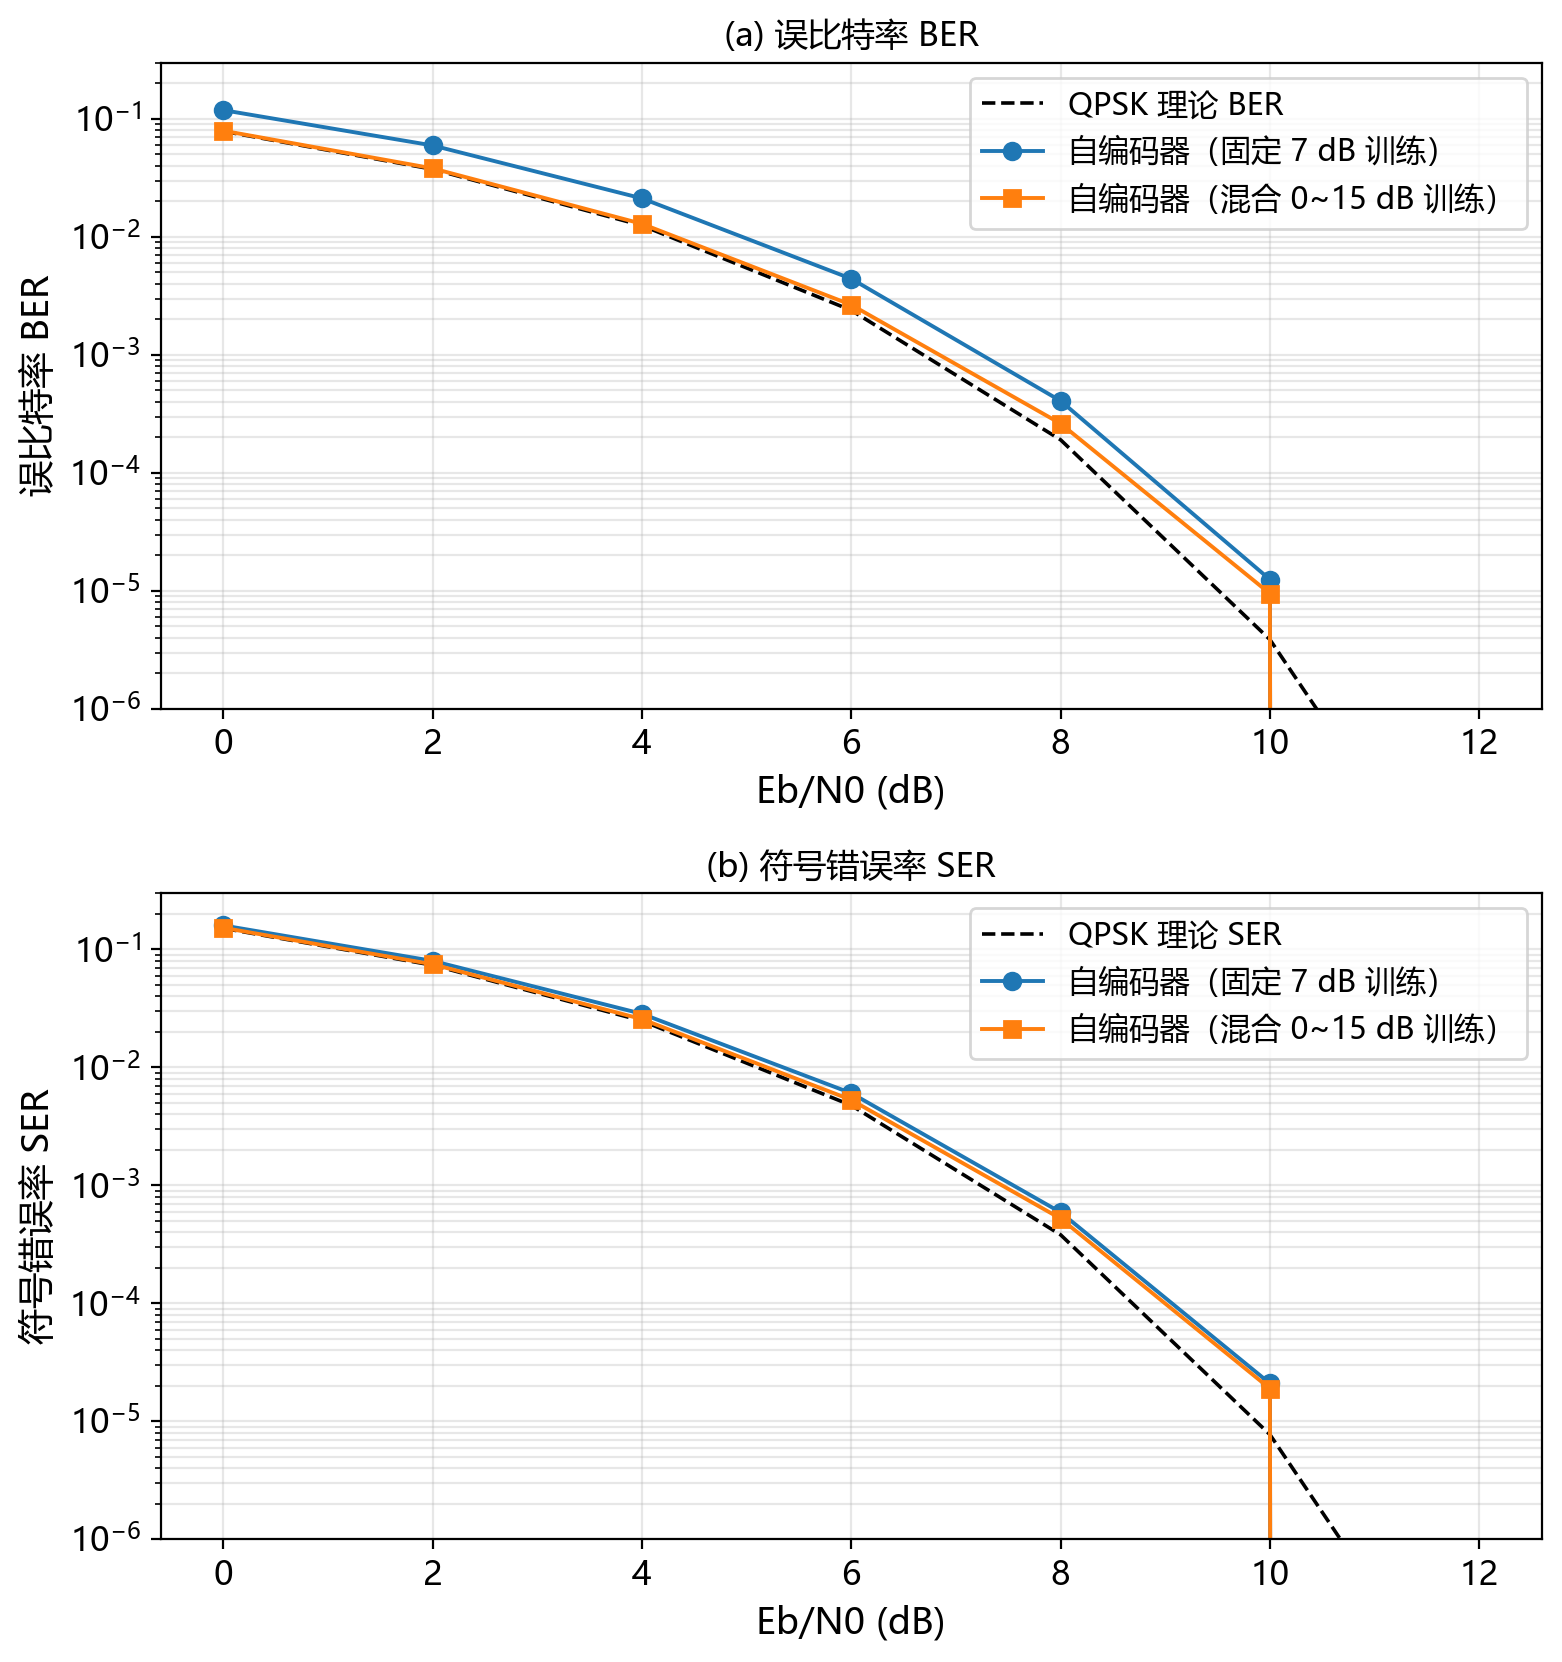

训练 7 dB 模型：BER 相对理论比值 = [1.51, 1.59, 1.7, 1.85, 2.14, 3.23, 0.0]
混合训练模型：BER 相对理论比值 = [1.01, 1.02, 1.03, 1.11, 1.37, 2.45, 0.0]


In [7]:
# 补充实验三：BER / SER 与理论曲线对比。
def evaluate_autoencoder(model, ebno_db_list, num_symbols=EVAL_SYMBOLS, chunk=EVAL_CHUNK):
    """返回 (Eb/N0, SER, BER)：每个点累计 num_symbols 个消息的符号/比特错误。"""
    rows = []
    for ebno_db in ebno_db_list:
        no = ebno_db_to_no(ebno_db, BITS_PER_SYMBOL)
        ser_err = ber_err = total = 0
        for _ in range(num_symbols // chunk):
            msg = torch.randint(
                0, M, (chunk,), dtype=torch.long, device=DEVICE, generator=EVAL_GENERATOR
            )
            with torch.no_grad():
                logits, _ = model(msg, no)
            pred = logits.argmax(dim=-1)
            ser_err += int((pred != msg).sum().item())
            ber_err += count_bit_errors(index_to_bits(msg), index_to_bits(pred))
            total += chunk
        rows.append((float(ebno_db), ser_err / total, ber_err / (total * BITS_PER_SYMBOL)))
    return rows


ebno_db = np.arange(0, 13, 2)

results_main = evaluate_autoencoder(model, ebno_db)        # 模板主模型：固定 7 dB 训练
results_mixed = evaluate_autoencoder(ae_mixed, ebno_db)    # 消融模型：混合 0~15 dB 训练
theory_ber = theory_qpsk_ber(ebno_db)
theory_ser = theory_qpsk_ser(ebno_db)

print("Eb/N0(dB)  理论BER    7dB训练BER   混合训练BER   理论SER    7dB训练SER   混合训练SER")
for (db, ser_m, ber_m), (_d, ser_x, ber_x) in zip(results_main, results_mixed):
    i = int(np.where(ebno_db == db)[0][0])
    print(
        f"{db:8.1f}  {theory_ber[i]:9.3e}  {ber_m:11.3e}  {ber_x:12.3e}  "
        f"{theory_ser[i]:9.3e}  {ser_m:10.3e}  {ser_x:12.3e}"
    )

fig, axes = plt.subplots(2, 1, figsize=(8, 8.5))

ax = axes[0]
ax.semilogy(ebno_db, theory_ber, "k--", lw=1.3, label="QPSK 理论 BER")
ax.semilogy(ebno_db, [r[2] for r in results_main], "o-", ms=6, lw=1.4, label="自编码器（固定 7 dB 训练）")
ax.semilogy(ebno_db, [r[2] for r in results_mixed], "s-", ms=6, lw=1.4, label="自编码器（混合 0~15 dB 训练）")
ax.set_xlabel("Eb/N0 (dB)")
ax.set_ylabel("误比特率 BER")
ax.set_ylim(1e-6, 3e-1)
ax.grid(True, which="both", alpha=0.3)
ax.legend()
ax.set_title("(a) 误比特率 BER", fontsize=12)

ax = axes[1]
ax.semilogy(ebno_db, theory_ser, "k--", lw=1.3, label="QPSK 理论 SER")
ax.semilogy(ebno_db, [r[1] for r in results_main], "o-", ms=6, lw=1.4, label="自编码器（固定 7 dB 训练）")
ax.semilogy(ebno_db, [r[1] for r in results_mixed], "s-", ms=6, lw=1.4, label="自编码器（混合 0~15 dB 训练）")
ax.set_xlabel("Eb/N0 (dB)")
ax.set_ylabel("符号错误率 SER")
ax.set_ylim(1e-6, 3e-1)
ax.grid(True, which="both", alpha=0.3)
ax.legend()
ax.set_title("(b) 符号错误率 SER", fontsize=12)

plt.tight_layout()
plt.savefig(FIG_DIR / "03J_ber_compare.png", dpi=200, bbox_inches="tight")
print("图题：端到端自编码器与 QPSK 理论的 BER / SER 对比")
plt.show()

rows_csv = []
for i, db in enumerate(ebno_db):
    rows_csv.append(
        {
            "ebno_db": float(db),
            "ber_theory_qpsk": float(theory_ber[i]),
            "ber_ae_train7db": results_main[i][2],
            "ber_ae_mixed": results_mixed[i][2],
            "ser_theory_qpsk": float(theory_ser[i]),
            "ser_ae_train7db": results_main[i][1],
            "ser_ae_mixed": results_mixed[i][1],
        }
    )
pd.DataFrame(rows_csv).to_csv(DATA_DIR / "03J_ber_compare.csv", index=False, encoding="utf-8-sig")

# 与理论曲线的差距（与理论 BER 的比值），给出可直接写进报告的量化结论
print("训练 7 dB 模型：BER 相对理论比值 =",
      [round(float(results_main[i][2] / theory_ber[i]), 2) for i in range(len(ebno_db))])
print("混合训练模型：BER 相对理论比值 =",
      [round(float(results_mixed[i][2] / theory_ber[i]), 2) for i in range(len(ebno_db))])

## 补充实验四：损失函数决定比特标号——消息级交叉熵 vs 比特级 BCE

模板给出的损失是**消息级交叉熵** $\mathcal{L}=-\log p(m\mid \mathbf{y})$。它对 $M$ 个消息的编号是**置换不变**的：
只要 $E_s=1$、点距最大，把消息 $0,1,2,3$ 换成任何排列，损失完全相同。因此网络可以收敛到接近最优的星座几何，
却把相邻的星座点贴上只差 2 个比特的标号（非 Gray 标号），使得符号错误率接近理论、比特错误率却明显变差。

对照方案是**比特级损失**：发射端把 $k=2$ 个比特线性映射成二维符号（比特标号本身也由梯度学出来），
接收端直接输出 $k$ 个比特 logits，用 `BCEWithLogitsLoss` 训练。下面比较两种损失学到的星座、标号结构（相邻点的 Hamming 距离）
以及最终的 BER；另外用“理想 Voronoi 检测器 + 学到的星座与标号”重算 BER，
以区分“接收机判决没学好”和“星座几何/标号本身有损”这两种可能。

比特级 BCE 训练 3000 步耗时 5.6 s；首次损失 0.6860，最后 100 步平均损失 0.0034


图题：消息级交叉熵与比特级 BCE 学到的星座及其比特标号（虚线连接相邻点）


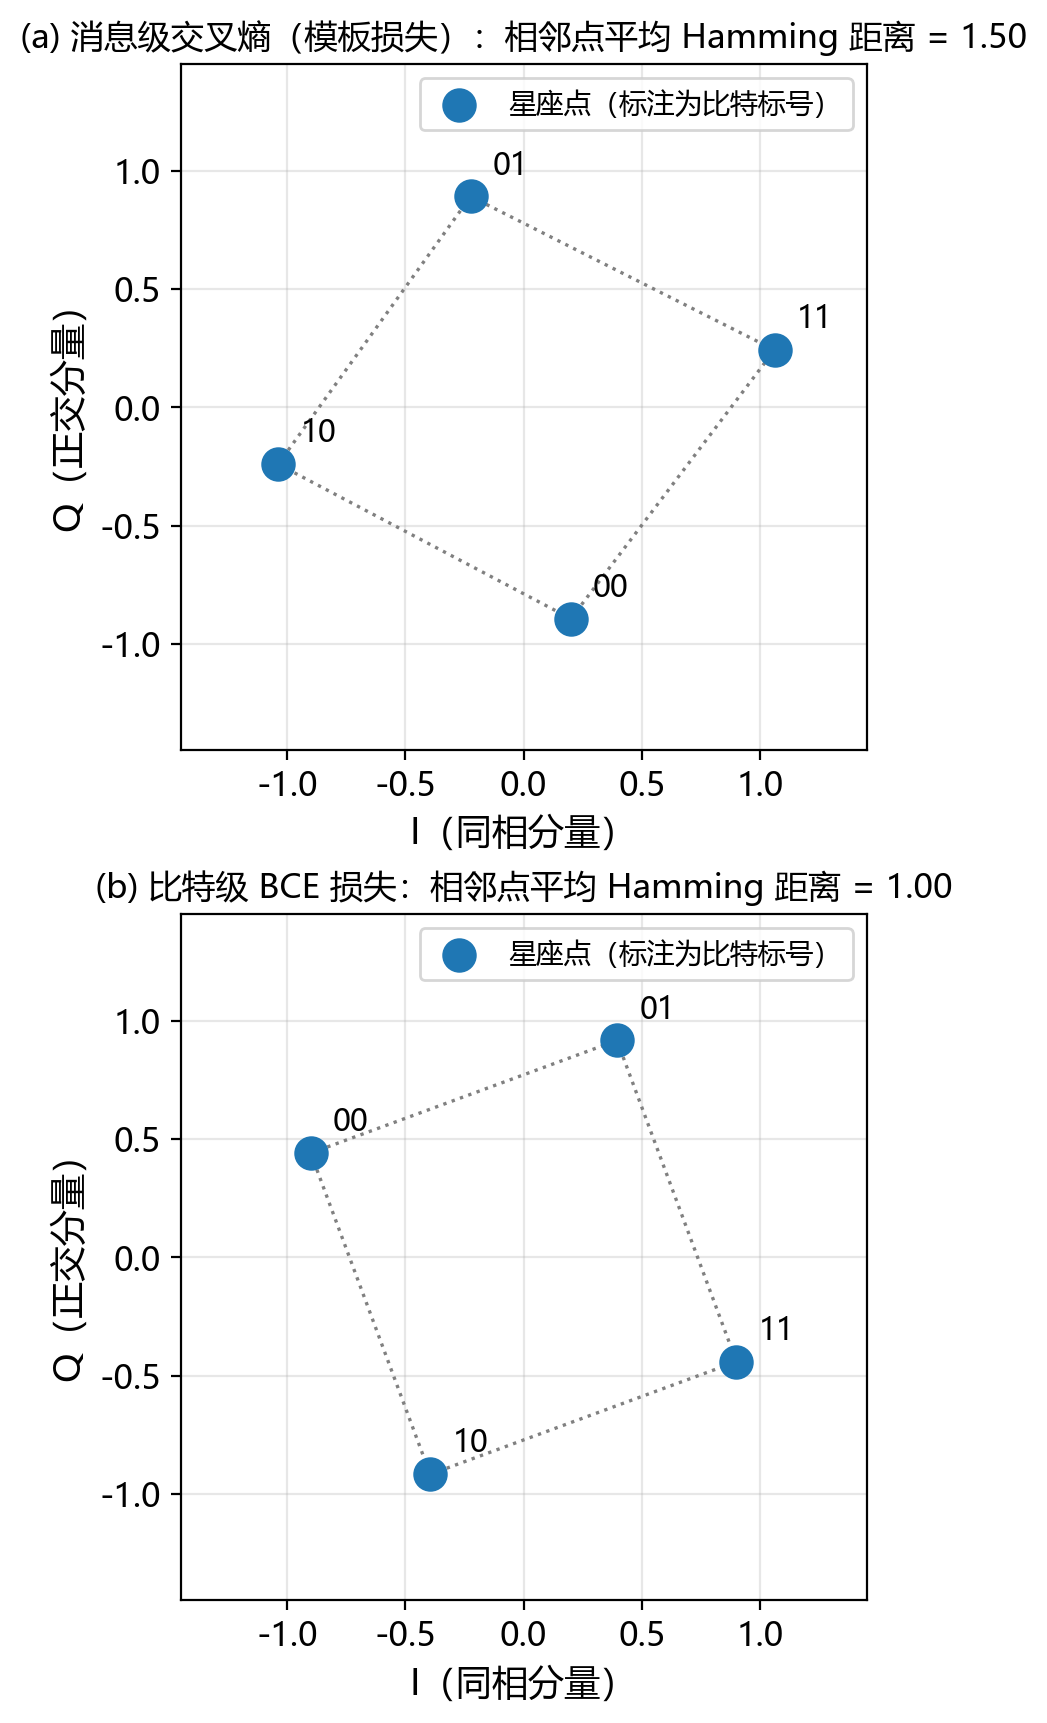

（相邻点对的定义：每个星座点取几何上最近的两个点，虚线即这些邻近关系）
消息级 CE：相邻点对 [(0, 2), (0, 3), (1, 2), (1, 3)]，平均 Hamming 距离 1.50（Gray 码应为 1.00）
比特级 BCE：相邻点对 [(0, 1), (0, 2), (1, 3), (2, 3)]，平均 Hamming 距离 1.00


In [8]:
# 补充实验四（a）：比特级 BCE 自编码器，以及两种损失的标号结构对比。
class BitAutoencoder(nn.Module):
    """比特级自编码器：k 个比特经线性层映射为二维连续符号（可学习星座），
    接收端 MLP 输出 k 个比特 logits，损失用 BCEWithLogits。"""

    def __init__(self, hidden_size=64):
        super().__init__()
        self.tx = nn.Linear(BITS_PER_SYMBOL, 2)
        self.receiver = nn.Sequential(
            nn.Linear(3, hidden_size),
            nn.ReLU(),
            nn.Linear(hidden_size, hidden_size),
            nn.ReLU(),
            nn.Linear(hidden_size, BITS_PER_SYMBOL),
        )

    def transmit(self, bits):
        z = 2.0 * bits.float() - 1.0
        p = self.tx(z)
        p = p - p.mean(dim=0, keepdim=True)
        return p / torch.sqrt(torch.mean(torch.sum(p**2, dim=1)) + 1e-12)

    def forward(self, bits, no, generator=None):
        x = self.transmit(bits)
        if generator is None:
            noise = torch.randn_like(x)
        else:
            noise = torch.randn(x.shape, dtype=torch.float32, generator=generator)
        no_t = torch.as_tensor(no, dtype=torch.float32, device=x.device)
        y = x + noise * torch.sqrt(no_t / 2.0)
        feat = torch.cat([y, torch.log10(no_t).expand(x.shape[0], 1)], dim=1)
        return self.receiver(feat), y


BIT_TRAIN_GENERATOR = torch.Generator(device="cpu").manual_seed(4321)
bit_model = BitAutoencoder().to(DEVICE)
opt = torch.optim.Adam(bit_model.parameters(), lr=1e-2)
no = ebno_db_to_no(EBNO_DB, BITS_PER_SYMBOL)
losses_bit = []
t0 = time.perf_counter()
for step in range(TRAIN_STEPS):
    bits = torch.randint(
        0, 2, (BATCH_SIZE, BITS_PER_SYMBOL), dtype=torch.long, device=DEVICE, generator=BIT_TRAIN_GENERATOR
    )
    logits_bit, _ = bit_model(bits, no, generator=BIT_TRAIN_GENERATOR)
    loss = F.binary_cross_entropy_with_logits(logits_bit, bits.float())
    opt.zero_grad()
    loss.backward()
    opt.step()
    losses_bit.append(float(loss.item()))
print(
    f"比特级 BCE 训练 {TRAIN_STEPS} 步耗时 {time.perf_counter() - t0:.1f} s；"
    f"首次损失 {losses_bit[0]:.4f}，最后 100 步平均损失 {np.mean(losses_bit[-100:]):.4f}"
)
pd.DataFrame({"step": np.arange(1, len(losses_bit) + 1), "loss_bce_bits": losses_bit}).to_csv(
    DATA_DIR / "03J_bitloss_train_loss.csv", index=False, encoding="utf-8-sig"
)

ALL_BITS = index_to_bits(torch.arange(M))
with torch.no_grad():
    pts_msg = model.constellation().cpu().numpy()
    pts_bit = bit_model.transmit(ALL_BITS).cpu().numpy()


def nearest_neighbour_pairs(pts, k=2):
    """相邻点对：每个星座点取几何上最近的 k 个点（k=2 对应方形星座的两个相邻点）。"""
    d = np.linalg.norm(pts[:, None, :] - pts[None, :, :], axis=-1)
    np.fill_diagonal(d, np.inf)
    pairs = set()
    for i in range(len(pts)):
        for j in np.argsort(d[i])[:k]:
            pairs.add((min(i, int(j)), max(i, int(j))))
    return sorted(pairs)


def mean_adjacent_hamming(bits_of_point, pairs):
    return float(np.mean([int(np.sum(bits_of_point[i] != bits_of_point[j])) for i, j in pairs]))


label_bits = ALL_BITS.numpy()  # 第 i 个比特模式 / 消息的标号比特
pairs_msg = nearest_neighbour_pairs(pts_msg)
pairs_bit = nearest_neighbour_pairs(pts_bit)
ham_msg = mean_adjacent_hamming(label_bits, pairs_msg)
ham_bit = mean_adjacent_hamming(label_bits, pairs_bit)

fig, axes = plt.subplots(2, 1, figsize=(8, 8.5), layout="constrained")
for ax, p, pairs, tag, name, ham in [
    (axes[0], pts_msg, pairs_msg, "a", "消息级交叉熵（模板损失）", ham_msg),
    (axes[1], pts_bit, pairs_bit, "b", "比特级 BCE 损失", ham_bit),
]:
    for i, (x, y) in enumerate(p):
        ax.annotate(format(i, "02b"), (x, y), xytext=(8, 8), textcoords="offset points", fontsize=11)
    for i, j in pairs:
        ax.plot([p[i, 0], p[j, 0]], [p[i, 1], p[j, 1]], ls=":", lw=1.2, c="gray")
    ax.scatter(p[:, 0], p[:, 1], s=130, zorder=3, label="星座点（标注为比特标号）")
    ax.set_xlim(-1.45, 1.45)
    ax.set_ylim(-1.45, 1.45)
    ax.set_aspect("equal", adjustable="box")
    ax.grid(alpha=0.3)
    ax.set_xlabel("I（同相分量）")
    ax.set_ylabel("Q（正交分量）")
    ax.set_title(f"({tag}) {name}：相邻点平均 Hamming 距离 = {ham:.2f}", fontsize=12)
    ax.legend(loc="upper right", fontsize=10)

plt.savefig(FIG_DIR / "03J_labeling_constellation.png", dpi=200, bbox_inches="tight")
print("图题：消息级交叉熵与比特级 BCE 学到的星座及其比特标号（虚线连接相邻点）")
plt.show()

print("（相邻点对的定义：每个星座点取几何上最近的两个点，虚线即这些邻近关系）")
print(f"消息级 CE：相邻点对 {pairs_msg}，平均 Hamming 距离 {ham_msg:.2f}（Gray 码应为 1.00）")
print(f"比特级 BCE：相邻点对 {pairs_bit}，平均 Hamming 距离 {ham_bit:.2f}")
pd.DataFrame(
    [
        ("msg_ce", i, p[0], p[1], format(i, "02b"))
        for i, p in enumerate(pts_msg)
    ]
    + [
        ("bit_bce", i, p[0], p[1], format(i, "02b"))
        for i, p in enumerate(pts_bit)
    ],
    columns=["model", "point", "I", "Q", "bits"],
).to_csv(DATA_DIR / "03J_labeling_constellation.csv", index=False, encoding="utf-8-sig")

Eb/N0(dB)  理论BER    消息级CE BER  比特级BCE BER  消息/理论  比特/理论
     0.0   7.865e-02     1.187e-01      7.966e-02       1.51      1.01
     2.0   3.751e-02     5.960e-02      3.819e-02       1.59      1.02
     4.0   1.250e-02     2.123e-02      1.291e-02       1.70      1.03
     6.0   2.388e-03     4.422e-03      2.593e-03       1.85      1.09
     8.0   1.909e-04     4.080e-04      2.050e-04       2.14      1.07
    10.0   3.872e-06     1.250e-05      6.000e-06       3.23      1.55
    12.0   9.006e-09     0.000e+00      0.000e+00       0.00      0.00

理想 Voronoi 检测器 + 消息级 CE 学到的星座与标号（说明 BER 差距不来自接收机）：
  Eb/N0= 0.0 dB：AE 接收机 BER=1.187e-01，理想 Voronoi BER=1.121e-01，相对差 +5.9%
  Eb/N0= 2.0 dB：AE 接收机 BER=5.960e-02，理想 Voronoi BER=5.544e-02，相对差 +7.5%
  Eb/N0= 4.0 dB：AE 接收机 BER=2.123e-02，理想 Voronoi BER=1.898e-02，相对差 +11.9%
  Eb/N0= 6.0 dB：AE 接收机 BER=4.422e-03，理想 Voronoi BER=3.651e-03，相对差 +21.1%
  Eb/N0= 8.0 dB：AE 接收机 BER=4.080e-04，理想 Voronoi BER=2.975e-04，相对差 +37.1%


图题：损失函数对端到端自编码器误比特率的影响（消息级 CE vs 比特级 BCE）


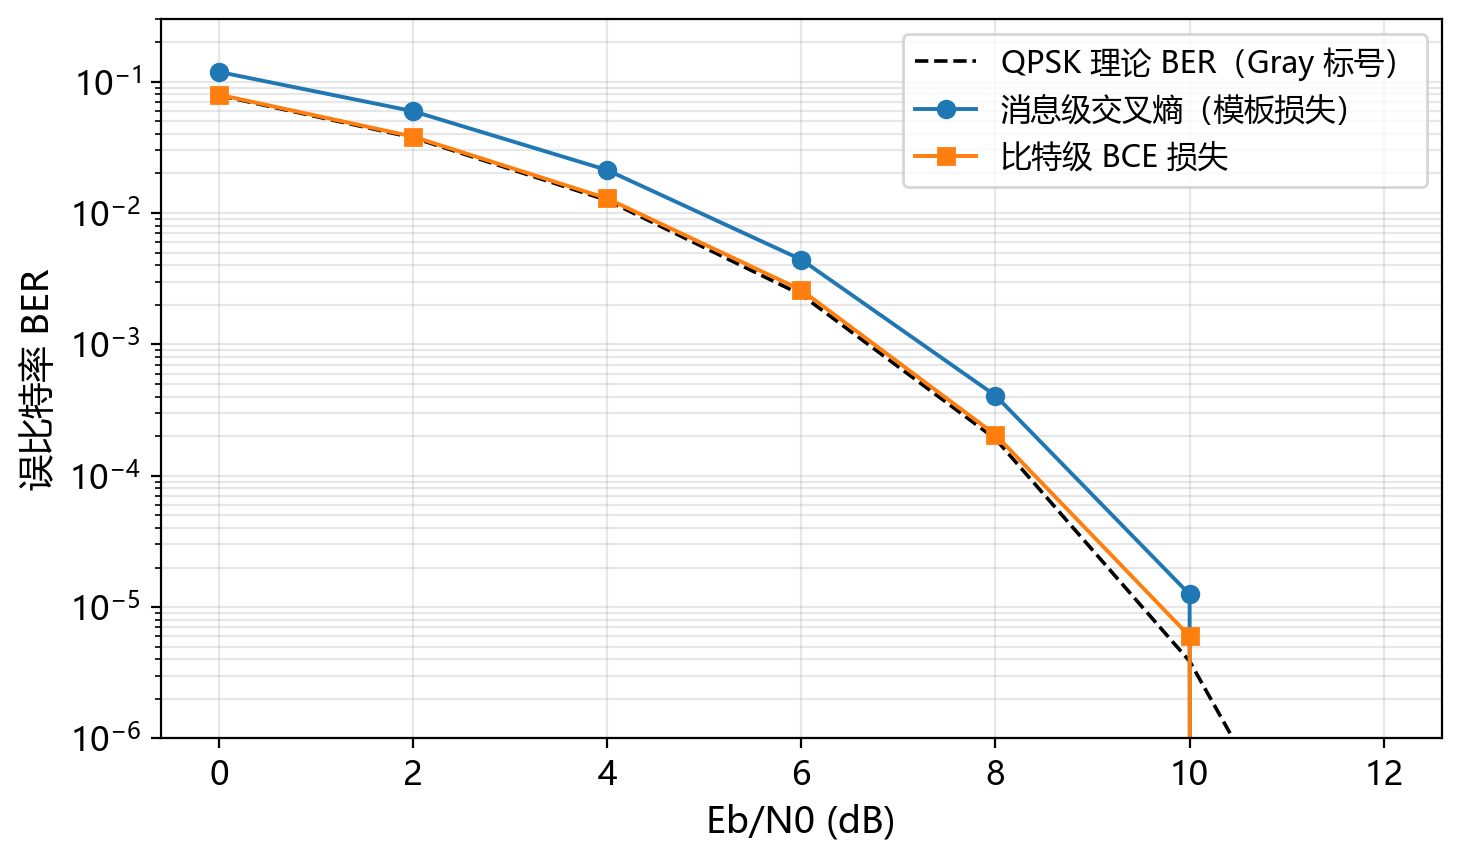

In [9]:
# 补充实验四（b）：BER 对比，并用理想 Voronoi 检测器做“判决质量分解”。
def evaluate_bit_autoencoder(model, ebno_db_list, num_symbols=EVAL_SYMBOLS, chunk=EVAL_CHUNK):
    gen = torch.Generator(device="cpu").manual_seed(777)
    rows = []
    for ebno_db in ebno_db_list:
        no = ebno_db_to_no(ebno_db, BITS_PER_SYMBOL)
        err = total = 0
        for _ in range(num_symbols // chunk):
            bits = torch.randint(
                0, 2, (chunk, BITS_PER_SYMBOL), dtype=torch.long, device=DEVICE, generator=gen
            )
            with torch.no_grad():
                logits_bit, _ = model(bits, no)
            pred = (logits_bit > 0).to(torch.int32)
            err += count_bit_errors(bits.to(torch.int32), pred)
            total += chunk
        rows.append((float(ebno_db), err / (total * BITS_PER_SYMBOL)))
    return rows


def ideal_voronoi_ber(pts, ebno_db_list, num_symbols=1_000_000, chunk=250_000):
    """理想最近邻检测器：星座几何与标号沿用学习结果，只把接收机换成最优判决，
    用来判断 BER 差距来自“接收机没学好”还是“星座几何+标号本身有损”。"""
    gen = torch.Generator(device="cpu").manual_seed(888)
    pts_t = torch.as_tensor(pts, dtype=torch.float32)
    msg_bits = ALL_BITS.to(torch.int32)
    rows = []
    for ebno_db in ebno_db_list:
        no = ebno_db_to_no(ebno_db, BITS_PER_SYMBOL)
        err = total = 0
        for _ in range(num_symbols // chunk):
            msg = torch.randint(0, M, (chunk,), dtype=torch.long, device=DEVICE, generator=gen)
            x = pts_t[msg]
            y = x + torch.randn(x.shape, generator=gen) * torch.sqrt(torch.as_tensor(no) / 2.0)
            q = torch.cdist(y, pts_t).argmin(dim=-1)
            err += count_bit_errors(msg_bits[msg], msg_bits[q])
            total += chunk
        rows.append((float(ebno_db), err / (total * BITS_PER_SYMBOL)))
    return rows


results_bit = evaluate_bit_autoencoder(bit_model, ebno_db)
voronoi_db = [0.0, 2.0, 4.0, 6.0, 8.0]
results_voronoi = ideal_voronoi_ber(pts_msg, voronoi_db)

print("Eb/N0(dB)  理论BER    消息级CE BER  比特级BCE BER  消息/理论  比特/理论")
for i, db in enumerate(ebno_db):
    t = theory_ber[i]
    print(
        f"{db:8.1f}  {t:10.3e}  {results_main[i][2]:12.3e}  {results_bit[i][1]:13.3e}  "
        f"{results_main[i][2] / t:9.2f}  {results_bit[i][1] / t:8.2f}"
    )

print("\n理想 Voronoi 检测器 + 消息级 CE 学到的星座与标号（说明 BER 差距不来自接收机）：")
for (db, b_v), (db2, _, b_ae) in zip(results_voronoi, [r for r in results_main if r[0] in voronoi_db]):
    rel = (b_ae - b_v) / b_v if b_v > 0 else float("nan")
    print(
        f"  Eb/N0={db:4.1f} dB：AE 接收机 BER={b_ae:.3e}，理想 Voronoi BER={b_v:.3e}，"
        f"相对差 {rel:+.1%}" if b_v > 0 else
        f"  Eb/N0={db:4.1f} dB：AE 接收机 BER={b_ae:.3e}，理想 Voronoi BER 样本中无错误（<1e-6 量级）"
    )

fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.semilogy(ebno_db, theory_ber, "k--", lw=1.3, label="QPSK 理论 BER（Gray 标号）")
ax.semilogy(ebno_db, [r[2] for r in results_main], "o-", ms=6, lw=1.4, label="消息级交叉熵（模板损失）")
ax.semilogy(ebno_db, [r[1] for r in results_bit], "s-", ms=6, lw=1.4, label="比特级 BCE 损失")
ax.set_xlabel("Eb/N0 (dB)")
ax.set_ylabel("误比特率 BER")
ax.set_ylim(1e-6, 3e-1)
ax.grid(True, which="both", alpha=0.3)
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "03J_labeling_ber.png", dpi=200, bbox_inches="tight")
print("图题：损失函数对端到端自编码器误比特率的影响（消息级 CE vs 比特级 BCE）")
plt.show()

rows_label = [
    {
        "ebno_db": float(ebno_db[i]),
        "ber_theory_gray": float(theory_ber[i]),
        "ber_msg_ce": results_main[i][2],
        "ber_bit_bce": results_bit[i][1],
        "ratio_msg_ce": results_main[i][2] / float(theory_ber[i]),
        "ratio_bit_bce": results_bit[i][1] / float(theory_ber[i]),
    }
    for i in range(len(ebno_db))
]
pd.DataFrame(rows_label).to_csv(DATA_DIR / "03J_labeling_ber.csv", index=False, encoding="utf-8-sig")
pd.DataFrame(
    {
        "model": ["msg_ce", "bit_bce"],
        "mean_adjacent_hamming": [ham_msg, ham_bit],
        "is_gray_like": [ham_msg <= 1.0 + 1e-9, ham_bit <= 1.0 + 1e-9],
    }
).to_csv(DATA_DIR / "03J_labeling_check.csv", index=False, encoding="utf-8-sig")